In [1]:
main_dir = "/home/gap2/Downloads/PPRL-Dev-main/results/random_configurations/metablocking/"
datasets= ["D2", "D3", "D4", "D8", "D9", "D10"]

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PRECISION = "Precision %"
RECALL = "Recall %"

def pareto_front(df, recall_threshold=85):
    # Keep only rows above the recall threshold
    df = df[df[RECALL] > recall_threshold]
    
    # Sort by precision (descending)
    df = df.sort_values(PRECISION, ascending=False)

    best_recall = -np.inf
    keep = []

    for idx, row in df.iterrows():
        if row[RECALL] > best_recall:
            keep.append(idx)
            best_recall = row[RECALL]

    return df.loc[keep].sort_values(PRECISION)

In [3]:
from numpy import trapz

def hypervolume(front):

    front = front.sort_values(PRECISION)

    return trapz(
        front[RECALL],
        front[PRECISION]
    )

In [4]:
def dominates(a, b):
    return (
        a[PRECISION] >= b[PRECISION]
        and a[RECALL] >= b[RECALL]
        and (
            a[PRECISION] > b[PRECISION]
            or a[RECALL] > b[RECALL]
        )
    )


def dominance_count(frontA, frontB):
    count = 0

    for _, pointB in frontB.iterrows():
        for _, pointA in frontA.iterrows():
            if dominates(pointA, pointB):
                count += 1
                break

    return count


def dominance_percentage(frontA, frontB):
    n = len(frontB)
    if n == 0:
        return 0.0

    return 100.0 * dominance_count(frontA, frontB) / n






D2


/tmp/ipykernel_11068/673135790.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


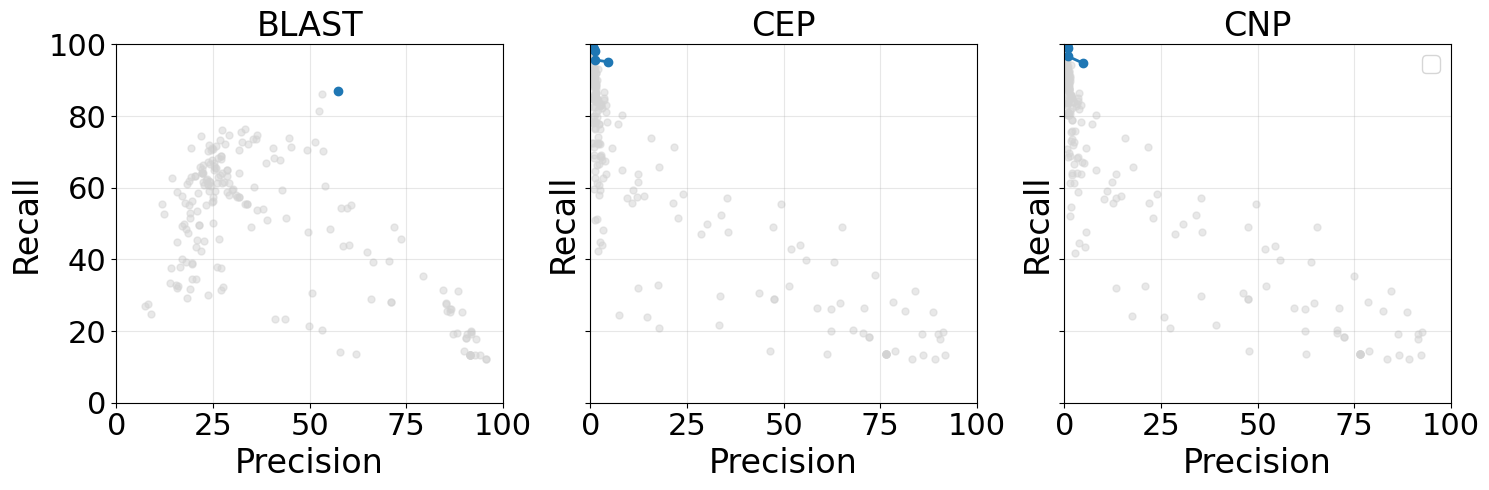

/tmp/ipykernel_11068/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_11068/673135790.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


BLAST 0.0
CEP 360.8696500000001
CNP 408.0934500000001
      BLAST    CEP    CNP
BLAST     -   0.0%   0.0%
CEP    0.0%      -  14.3%
CNP    0.0%  33.3%      -





D3


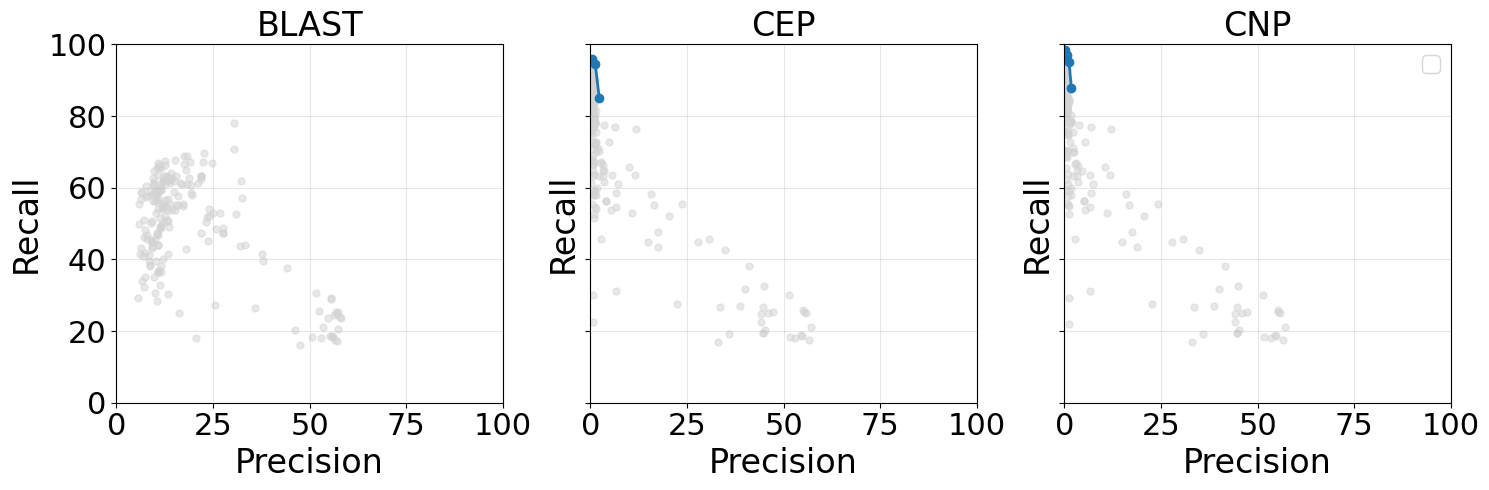

/tmp/ipykernel_11068/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_11068/673135790.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


BLAST 0.0
CEP 175.2698
CNP 142.6806
      BLAST    CEP   CNP
BLAST     -   0.0%  0.0%
CEP    0.0%      -  0.0%
CNP    0.0%  33.3%     -





D4


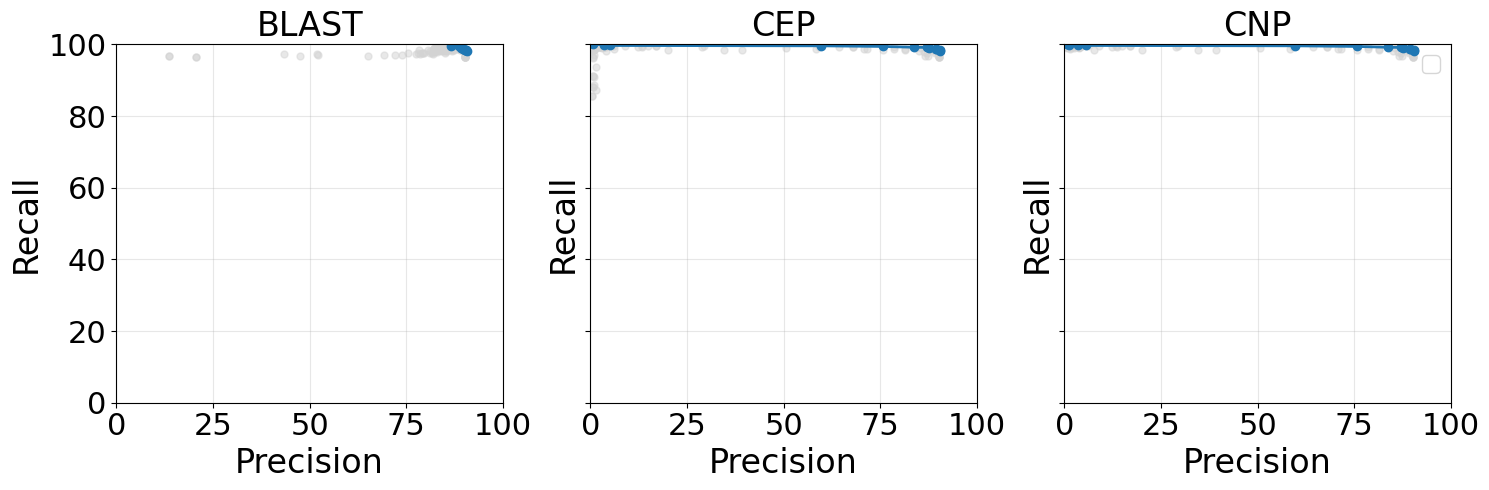

/tmp/ipykernel_11068/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_11068/673135790.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


BLAST 393.7108999999998
CEP 8930.900099999999
CNP 8940.941299999999
      BLAST    CEP    CNP
BLAST     -  66.7%  61.5%
CEP    0.0%      -   7.7%
CNP    0.0%  16.7%      -





D8


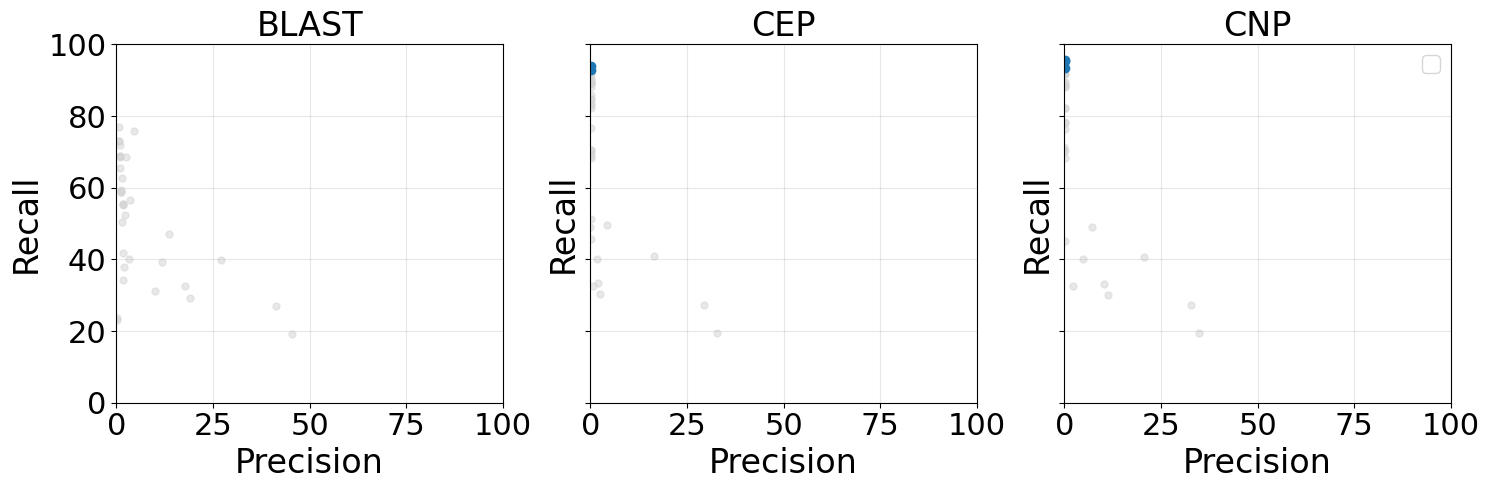

/tmp/ipykernel_11068/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(


BLAST 0.0
CEP 9.3375
CNP 4.732100000000001
      BLAST    CEP   CNP
BLAST     -   0.0%  0.0%
CEP    0.0%      -  0.0%
CNP    0.0%  50.0%     -





D9


FileNotFoundError: [Errno 2] No such file or directory: '/home/gap2/Downloads/PPRL-Dev-main/results/random_configurations/metablocking/D9/BLAST.csv'

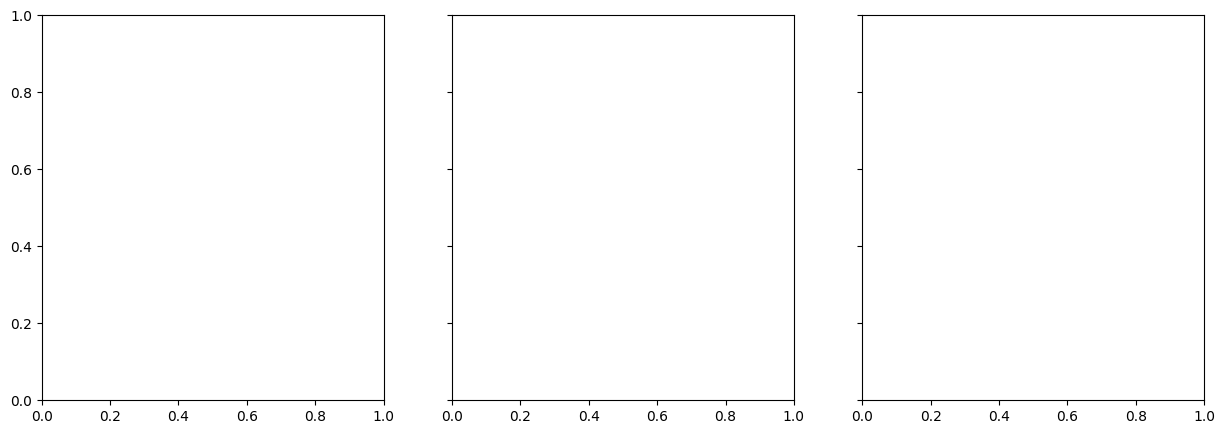

In [5]:
for dataset in datasets:
    print("\n\n\n\n\n" + dataset)
    
    files = {
        "BLAST": main_dir + dataset + "/BLAST.csv",
        "CEP": main_dir +  dataset + "/CardinalityEdgePruning.csv",
        "CNP": main_dir +  dataset + "/CardinalityNodePruning.csv",
        "WEP": main_dir +  dataset + "/WeightedEdgePruning.csv",
        "WNP": main_dir +  dataset + "/WeightedNodePruning.csv"
    }

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 5),
        sharex=True,
        sharey=True
    )

    pareto = {} 
    for ax, (title, filename) in zip(axes, files.items()):

        df = pd.read_csv(filename)
        pf = pareto_front(df)
        pareto[title] = pf
        
        # All experiments
        ax.scatter(
            df[PRECISION],
            df[RECALL],
            color="lightgray",
            alpha=0.5,
            s=25
        )

        # Pareto front
        ax.plot(
            pf[PRECISION],
            pf[RECALL],
            "-o",
            linewidth=2,
            markersize=6
        )

        ax.set_title(title, fontsize=24)
        ax.set_xlabel("Precision", fontsize=24)
        ax.set_ylabel("Recall", fontsize=24)
        ax.tick_params(axis='both', labelsize=22)

        ax.grid(alpha=0.3)
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 100)

    axes[0].set_ylabel("Recall")

    for ax in axes:
        ax.set_xlabel("Precision")
        
    ax.legend(fontsize=16)

    plt.tight_layout()
    plt.show()
    
    for name, pf in pareto.items():
        print(name, hypervolume(pf)) #higher is better
        
    names = list(pareto.keys())

    table = pd.DataFrame(
        index=names,
        columns=names
    )

    for A in names:
        for B in names:

            if A == B:
                table.loc[A,B] = "-"

            else:
                table.loc[A, B] = f"{dominance_percentage(pareto[A], pareto[B]):.1f}%"

    print(table)

In [6]:
from IPython.display import display, HTML

for dataset in datasets:
    all_summaries = []
    print("\n\n\n" + dataset)
    for threshold in [85, 90, 95]:
        files = {
            "BLAST": main_dir + dataset + "/BLAST.csv",
            "CEP": main_dir +  dataset + "/CardinalityEdgePruning.csv",
            "CNP": main_dir +  dataset + "/CardinalityNodePruning.csv",
            "WEP": main_dir +  dataset + "/WeightedEdgePruning.csv",
            "WNP": main_dir +  dataset + "/WeightedNodePruning.csv"
        }

        for name, filename in files.items():
            df = pd.read_csv(filename)
            valid = df[df["Recall %"] >= threshold]

            if valid.empty:
                continue

            best = valid.loc[valid["Precision %"].idxmax()].to_dict()
            best["Method"] = name
            best["Dataset"] = dataset

            all_summaries.append(best)

        summary_df = pd.DataFrame(all_summaries)

    display(
        HTML(
            f"""
            <div style="overflow-x:auto; width:100%;">
                {pd.DataFrame(all_summaries).to_html()}
            </div>
            """
        )
    )




D2


,name,weighting_scheme,runtime,candidate_pairs,lsh_config,filtering_config,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset
0,BLAST,CN-CBS,0.25,1611,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Purging', 'smoothing_factor': 0.9}",57.42,86.94,69.16,925,686,937,139,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",BLAST,D2
1,CardinalityEdgePruning,CN-CBS,0.04,22420,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.2}",4.51,95.11,8.62,1012,21408,1024,52,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",CEP,D2
2,CardinalityNodePruning,CN-CBS,0.08,20925,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.2}",4.82,94.74,9.17,1008,19917,1020,56,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",CNP,D2
3,Weighted Edge Pruning,CN-CBS,0.04,3463,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.2}",26.19,85.24,40.07,907,2556,919,157,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WEP,D2
4,Weighted Node Pruning,CN-CBS,0.03,7565,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.2}",12.89,91.64,22.60,975,6590,987,89,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WNP,D2
5,CardinalityEdgePruning,CN-CBS,0.04,22420,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.2}",4.51,95.11,8.62,1012,21408,1024,52,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",CEP,D2
6,CardinalityNodePruning,CN-CBS,0.08,20925,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.2}",4.82,94.74,9.17,1008,19917,1020,56,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",CNP,D2
7,Weighted Edge Pruning,CN-CBS,0.09,31378,"{'psi': 9, 'lambda': 134, 'distance_threshold': 204}","{'method': 'Block Filtering', 'ratio': 0.4}",3.09,91.07,5.97,969,30409,981,95,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 3, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WEP,D2
8,Weighted Node Pruning,CN-CBS,0.03,7565,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.2}",12.89,91.64,22.60,975,6590,987,89,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WNP,D2
9,CardinalityEdgePruning,CN-CBS,0.04,22420,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.2}",4.51,95.11,8.62,1012,21408,1024,52,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",CEP,D2





D3


,name,weighting_scheme,runtime,candidate_pairs,lsh_config,filtering_config,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset
0,CardinalityEdgePruning,CN-CBS,0.07,40899,"{'psi': 12, 'lambda': 110, 'distance_threshold': 76}","{'method': 'Block Filtering', 'ratio': 0.2}",2.29,85.03,4.46,937,39962,3022,165,"{'attributes': ['title'], 'size': 256, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",CEP,D3
1,CardinalityNodePruning,CN-CBS,0.18,54103,"{'psi': 12, 'lambda': 110, 'distance_threshold': 76}","{'method': 'Block Filtering', 'ratio': 0.2}",1.79,87.93,3.51,969,53134,3054,133,"{'attributes': ['title'], 'size': 256, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",CNP,D3
2,Weighted Edge Pruning,CN-CBS,0.10,20327,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Filtering', 'ratio': 0.5}",4.90,90.47,9.31,997,19330,3082,105,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",WEP,D3
3,Weighted Node Pruning,CN-CBS,0.09,36866,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Filtering', 'ratio': 0.5}",2.77,92.65,5.38,1021,35845,3106,81,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",WNP,D3
4,CardinalityEdgePruning,CN-CBS,0.12,84767,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Filtering', 'ratio': 0.5}",1.23,94.65,2.43,1043,83724,3128,59,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",CEP,D3
5,CardinalityNodePruning,CN-CBS,0.22,87653,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Filtering', 'ratio': 0.5}",1.19,95.01,2.36,1047,86606,3132,55,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",CNP,D3
6,Weighted Edge Pruning,CN-CBS,0.10,20327,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Filtering', 'ratio': 0.5}",4.90,90.47,9.31,997,19330,3082,105,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",WEP,D3
7,Weighted Node Pruning,CN-CBS,0.09,36866,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Filtering', 'ratio': 0.5}",2.77,92.65,5.38,1021,35845,3106,81,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",WNP,D3
8,CardinalityEdgePruning,CN-CBS,0.77,272904,"{'psi': 9, 'lambda': 134, 'distance_threshold': 102}","{'method': 'Block Purging', 'smoothing_factor': 0.9}",0.39,95.92,0.77,1057,271847,3142,45,"{'attributes': ['title'], 'size': 256, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",CEP,D3
9,CardinalityNodePruning,CN-CBS,0.22,87653,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Filtering', 'ratio': 0.5}",1.19,95.01,2.36,1047,86606,3132,55,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",CNP,D3





D4


,name,weighting_scheme,runtime,candidate_pairs,lsh_config,filtering_config,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset
0,BLAST,CN-CBS,0.12,2395,"{'psi': 43, 'lambda': 143, 'distance_threshold': 12}","{'method': 'Block Filtering', 'ratio': 0.6}",90.65,98.06,94.21,2171,224,2591,43,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",BLAST,D4
1,CardinalityEdgePruning,CN-CBS,0.16,2401,"{'psi': 43, 'lambda': 143, 'distance_threshold': 12}","{'method': 'Block Filtering', 'ratio': 0.6}",90.46,98.10,94.13,2172,229,2592,42,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",CEP,D4
2,CardinalityNodePruning,CN-CBS,0.17,2401,"{'psi': 43, 'lambda': 143, 'distance_threshold': 12}","{'method': 'Block Filtering', 'ratio': 0.6}",90.46,98.10,94.13,2172,229,2592,42,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",CNP,D4
3,Weighted Edge Pruning,CN-CBS,0.14,1966,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Filtering', 'ratio': 0.3}",99.95,88.75,94.02,1965,1,2385,249,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 5, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",WEP,D4
4,Weighted Node Pruning,CN-CBS,0.06,2237,"{'psi': 43, 'lambda': 143, 'distance_threshold': 6}","{'method': 'Block Filtering', 'ratio': 0.2}",95.26,96.25,95.75,2131,106,2551,83,"{'attributes': ['title'], 'size': 64, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WNP,D4
5,BLAST,CN-CBS,0.12,2395,"{'psi': 43, 'lambda': 143, 'distance_threshold': 12}","{'method': 'Block Filtering', 'ratio': 0.6}",90.65,98.06,94.21,2171,224,2591,43,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",BLAST,D4
6,CardinalityEdgePruning,CN-CBS,0.16,2401,"{'psi': 43, 'lambda': 143, 'distance_threshold': 12}","{'method': 'Block Filtering', 'ratio': 0.6}",90.46,98.10,94.13,2172,229,2592,42,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",CEP,D4
7,CardinalityNodePruning,CN-CBS,0.17,2401,"{'psi': 43, 'lambda': 143, 'distance_threshold': 12}","{'method': 'Block Filtering', 'ratio': 0.6}",90.46,98.10,94.13,2172,229,2592,42,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",CNP,D4
8,Weighted Edge Pruning,CN-CBS,0.13,2015,"{'psi': 19, 'lambda': 125, 'distance_threshold': 204}","{'method': 'Block Filtering', 'ratio': 0.6}",99.90,90.92,95.20,2013,2,2433,201,"{'attributes': ['title'], 'size': 1024, 'offset': 0, 'num_hashes': 28, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",WEP,D4
9,Weighted Node Pruning,CN-CBS,0.06,2237,"{'psi': 43, 'lambda': 143, 'distance_threshold': 6}","{'method': 'Block Filtering', 'ratio': 0.2}",95.26,96.25,95.75,2131,106,2551,83,"{'attributes': ['title'], 'size': 64, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WNP,D4





D8


,name,weighting_scheme,runtime,candidate_pairs,lsh_config,filtering_config,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset
0,CardinalityEdgePruning,CN-CBS,1.23,573389,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Purging', 'smoothing_factor': 0.9}",0.14,92.85,0.28,792,572597,23708,61,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",CEP,D8
1,CardinalityNodePruning,CN-CBS,2.86,950833,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Purging', 'smoothing_factor': 0.9}",0.08,93.43,0.17,797,950036,23713,56,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",CNP,D8
2,Weighted Edge Pruning,CN-CBS,0.77,386928,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.5}",0.20,89.80,0.40,766,386162,23682,87,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",WEP,D8
3,Weighted Node Pruning,CN-CBS,1.07,524147,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.5}",0.15,90.39,0.29,771,523376,23687,82,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",WNP,D8
4,CardinalityEdgePruning,CN-CBS,1.23,573389,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Purging', 'smoothing_factor': 0.9}",0.14,92.85,0.28,792,572597,23708,61,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",CEP,D8
5,CardinalityNodePruning,CN-CBS,2.86,950833,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Purging', 'smoothing_factor': 0.9}",0.08,93.43,0.17,797,950036,23713,56,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",CNP,D8
6,WeightedEdgePruning,CN-CBS,1.68,727351,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Purging', 'smoothing_factor': 0.9}",0.11,93.08,0.22,794,726557,23710,59,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WEP,D8
7,Weighted Node Pruning,CN-CBS,1.07,524147,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.5}",0.15,90.39,0.29,771,523376,23687,82,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",WNP,D8
8,CardinalityNodePruning,CN-CBS,9.76,2116419,"{'psi': 12, 'lambda': 110, 'distance_threshold': 76}","{'method': 'Block Purging', 'smoothing_factor': 0.9}",0.04,95.43,0.08,814,2115605,23730,39,"{'attributes': ['title'], 'size': 256, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",CNP,D8
9,Weighted Edge Pruning,CN-CBS,2.19,1399987,"{'psi': 12, 'lambda': 115, 'distance_threshold': 307}","{'method': 'Block Filtering', 'ratio': 0.6}",0.06,95.08,0.12,811,1399176,23727,42,"{'attributes': ['title'], 'size': 1024, 'offset': 0, 'num_hashes': 4, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",WEP,D8





D9


FileNotFoundError: [Errno 2] No such file or directory: '/home/gap2/Downloads/PPRL-Dev-main/results/random_configurations/metablocking/D9/BLAST.csv'